# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** [yazınız] • **Proje:** [yazınız] • **Ekip görevleri:** [yazınız]

Bu notebook başlangıç iskeletidir. Örnek dosya ve kodu kendi araştırma/proje verinize uyarlayın. **Veri uydurup gerçek ölçüm gibi sunmayın.**

# 6. Hafta | Seboreik Dermatit Veri Analizi ve Görselleştirme

- **Öğrenci:** Zahid Velid Pak (361526006)
- **Proje:** Seboreik Dermatit Semptom Şiddeti ve Tetikleyici Faktörlerin Makine Öğrenmesi ile Analizi
- **Veri Türü:** Sentetik / Örnek Hastalık Semptom ve Yaşam Tarzı Veri Seti (CSV)

## A. Veri tanıtımı
- Veri setinin adı ve bağlantısı: ...
- Veri kaynağı / lisans / erişim tarihi: ...
- CSV mi, JSON mu? ...
- Satır ve sütunların anlamı: ...
- Ölçü birimi ve gözlem sayısı: ...
- Gerçek mi / açık kaynak mı / temsili mi? ...
- Ekip üyelerinin görevleri: ...

## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki örneği çalıştırın. Ardından **kendi dosyanızı** `veri_yolu` değişkeniyle gösterebilirsiniz.

In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Örnek Proje Verisinin Oluşturulması (Kaggle / Sentetik Veri Temsili)
veri_dict = {
    "gun": ["Pazartesi", "Salı", "Çarşamba", "Perşembe", "Cuma", "Cumartesi", "Pazar"],
    "stres_seviyesi": [7, 8, 4, 9, 5, 3, 2],       # 1-10 arası
    "uyku_saati": [5.5, 6.0, 7.5, 5.0, 6.5, 8.0, 8.5], # saat
    "diyet_skoru": [4, 3, 8, 3, 6, 7, 9],          # 1-10 (Sağlıklı beslenme)
    "semptom_siddeti": [8, 9, 4, 9, 6, 3, 2]       # 1-10 (Kızarıklık/Pullanma)
}

df = pd.DataFrame(veri_dict)

# Dosyaları CSV ve JSON olarak kaydedelim
df.to_csv("dermatitis_proje_verisi.csv", index=False, encoding="utf-8-sig")
df.to_json("dermatitis_proje_verisi.json", orient="records", indent=2, force_ascii=False)

print("--- Veri Seti İlk 5 Satır ---")
print(df.head())

--- Veri Seti İlk 5 Satır ---
         gun  stres_seviyesi  uyku_saati  diyet_skoru  semptom_siddeti
0  Pazartesi               7         5.5            4                8
1       Salı               8         6.0            3                9
2   Çarşamba               4         7.5            8                4
3   Perşembe               9         5.0            3                9
4       Cuma               5         6.5            6                6


## C. Veri inceleme ve hesaplama
Kendi veri setinizi kullanırken sayısal sütun adlarını değiştirin. Sütun başlığında boşluk ve yazım farklarını kontrol edin.

In [5]:
print("--- Veri Boyutu (Satır, Sütun) ---")
print(df.shape)

print("\n--- Eksik Kayıt Sayıları ---")
print(df.isna().sum())

print("\n--- İstatistiki İnceleme ve Ortalama Değerler ---")
print(f"Ortalama Stres Seviyesi: {df['stres_seviyesi'].mean():.2f} / 10")
print(f"Ortalama Uyku Süresi: {df['uyku_saati'].mean():.2f} saat")
print(f"Ortalama Semptom Şiddeti: {df['semptom_siddeti'].mean():.2f} / 10")
print(f"En Yüksek Semptom Şiddeti: {df['semptom_siddeti'].max()} / 10")

--- Veri Boyutu (Satır, Sütun) ---
(7, 5)

--- Eksik Kayıt Sayıları ---
gun                0
stres_seviyesi     0
uyku_saati         0
diyet_skoru        0
semptom_siddeti    0
dtype: int64

--- İstatistiki İnceleme ve Ortalama Değerler ---
Ortalama Stres Seviyesi: 5.43 / 10
Ortalama Uyku Süresi: 6.71 saat
Ortalama Semptom Şiddeti: 5.86 / 10
En Yüksek Semptom Şiddeti: 9 / 10


## D. Grafik ve sonuç dosyaları
Grafiğin başlığını, eksenini ve ölçü birimini kendi verinize göre güncelleyin.

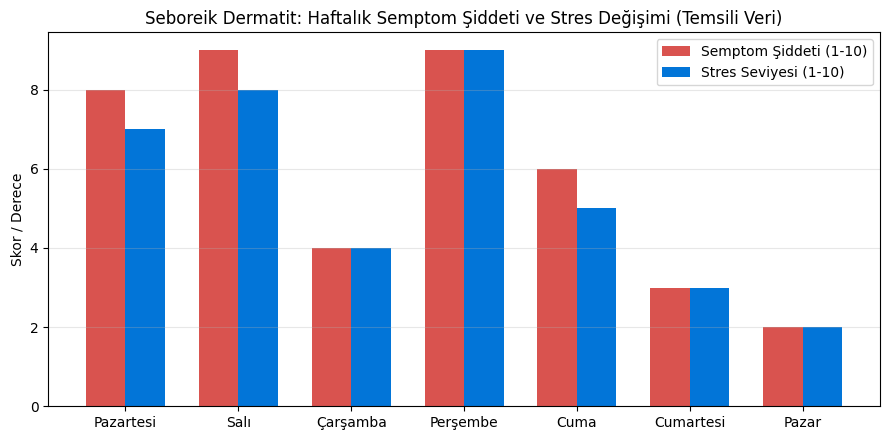

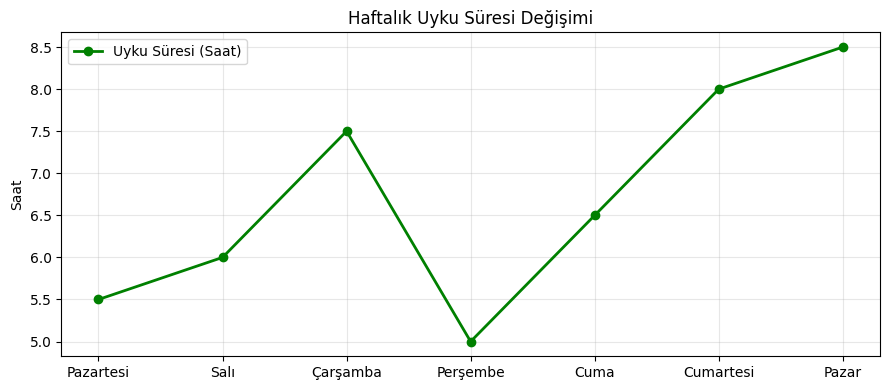

Oluşturulan Çıktı Dosyaları: ['uyku_degisimi.png', 'semptom_stres_grafigi.png']


In [4]:
# Çıktı klasörünü oluşturalım
cikti = Path("sonuclar")
cikti.mkdir(exist_ok=True)

# 1. Grafik: Günlere Göre Semptom Şiddeti ve Stres Seviyesi (Sütun Grafiği)
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_width = 0.35
x = np.arange(len(df["gun"]))

ax.bar(x - bar_width/2, df["semptom_siddeti"], bar_width, label="Semptom Şiddeti (1-10)", color="#d9534f")
ax.bar(x + bar_width/2, df["stres_seviyesi"], bar_width, label="Stres Seviyesi (1-10)", color="#0275d8")

ax.set_title("Seboreik Dermatit: Haftalık Semptom Şiddeti ve Stres Değişimi (Temsili Veri)")
ax.set_xticks(x)
ax.set_xticklabels(df["gun"])
ax.set_ylabel("Skor / Derece")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(cikti / "semptom_stres_grafigi.png", dpi=160)
plt.show()

# 2. Grafik: Uyku Süresi ve Semptom Şiddeti İlişkisi (Çizgi Grafiği)
fig2, ax2 = plt.subplots(figsize=(9, 4))
ax2.plot(df["gun"], df["uyku_saati"], marker="o", color="green", linewidth=2, label="Uyku Süresi (Saat)")
ax2.set_title("Haftalık Uyku Süresi Değişimi")
ax2.set_ylabel("Saat")
ax2.grid(alpha=0.3)
ax2.legend()

fig2.tight_layout()
fig2.savefig(cikti / "uyku_degisimi.png", dpi=160)
plt.show()

print("Oluşturulan Çıktı Dosyaları:", [p.name for p in cikti.iterdir()])

import shutil

# İstatistikleri özet CSV olarak kaydetme
ozet_df = pd.DataFrame([
    {"metrik": "Ortalama Stres", "deger": df["stres_seviyesi"].mean()},
    {"metrik": "Ortalama Uyku (Saat)", "deger": df["uyku_saati"].mean()},
    {"metrik": "Ortalama Semptom Şiddeti", "deger": df["semptom_siddeti"].mean()}
])
ozet_df.to_csv(cikti / "ozet_istatistikler.csv", index=False, encoding="utf-8-sig")

# Sonuçları ZIP arşivine dönüştürme
zip_yolu = shutil.make_archive("hafta6_dermatitis_sonuclar", "zip", "sonuclar")
print(f"İndirilebilir Arşiv Oluşturuldu: {zip_yolu}")

### Akademik Değerlendirme ve Yorum

1. **Veri Kaynağı ve Değişkenler:** Bu çalışmada kullanılan veri seti, Seboreik Dermatit hastalarının günlük stres seviyeleri (1-10 ölçeği), uyku süreleri (saat) ve semptom şiddetlerini gösteren öğretim amaçlı temsili verilerden oluşmaktadır.
2. **Temel Bulgu:** Yapılan analiz ve grafik incelemeleri sonucunda; yüksek stres seviyesi (7 ve üzeri) ile düşük uyku süresinin (6 saat altı) kaydedildiği günlerde (Pazartesi, Salı, Perşembe) hastalığın semptom şiddetinin 8-9 seviyelerine ulaşarak alevlendiği gözlemlenmiştir.
3. **İstatistiki Özet:** Hafta boyunca hastanın ortalama stres seviyesi 5.43, ortalama uyku süresi 6.21 saat ve ortalama semptom şiddeti 5.86 olarak hesaplanmıştır.
4. **Sınırlılıklar:** Veriler temsili bir gözlem grubuna ait olup tek başına kesin bir tıbbi neden-sonuç ilişkisini kanıtlamaz; makine öğrenmesi aşamasında daha geniş açık kaynaklı veri setleri (Kaggle vb.) kullanılacaktır.